In [1]:
from typing import Literal, Tuple

import os
import re
import warnings
import anndata as ad
import scanpy as sc
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as mpl
import matplotlib.cm as cm
import matplotlib.lines as mlines 
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from matplotlib.figure import Figure
from matplotlib.text import Text
from matplotlib.collections import LineCollection
from bokeh.palettes import all_palettes
from upsetplot import from_memberships, UpSet
from anndata import AnnData
from upsetplot import plot

In [2]:
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['font.sans-serif'] = ['Arial'] # Ensure 'Arial' is in the sans-serif list

In [9]:
fig_path = "/Users/soeren.becker/repos/HumanCytokineDict/notebooks/04_gene_programs/manuscript_figures"

In [10]:
greek_map = {
    "alpha": "α",
    "beta": "β",
    "gamma": "γ",
    "epsilon": "ε",
    "lambda": "λ",
    "omega": "ω"
}

def replace_greek_words_with_unicode(text, greek_map=greek_map):
    for word, symbol in greek_map.items():
        text = text.replace(word, symbol)
    return text

def _get_num_programs(
    df_prog: pd.DataFrame,
    direction: Literal["up", "down"],
    threshold: float = 0,
):
    mask = df_prog.activity > threshold if direction == "up" else df_prog.activity < threshold
    _df_prog = df_prog.loc[mask]
    _df_prog = _df_prog.groupby(["cell_type", "program"], observed=False).cyt.nunique().reset_index()
    _df_prog = _df_prog.rename({"cyt": "num_cytokines"}, axis=1)
    _df_prog = _df_prog.pivot(index="cell_type", columns="program", values="num_cytokines")
    return _df_prog

def get_num_programs(df_scores: pd.DataFrame):
    df_prog = df_scores.set_index(["cell_type", "cyt"]).stack().reset_index()
    df_prog = df_prog.rename({"level_2": "program", 0: "activity"}, axis=1)
    df_prog_up = _get_num_programs(df_prog, direction="up", threshold=0)
    df_prog_down = _get_num_programs(df_prog, direction="down", threshold=0)
    assert np.all(df_prog_up.index == df_prog_down.index)
    return df_prog_up, df_prog_down

def get_program_names(
    label: list | Text | str, 
    program_annotations: pd.DataFrame
) -> list[str] | str:
    if isinstance(label, list):
        return [get_program_names(l, program_annotations) for l in label]
    elif isinstance(label, Text):
        label = label.get_text()
    assert isinstance(label, str), type(label)
    label = label.replace("DR ", "P")
    new_label = program_annotations.loc[(program_annotations.Program == label), "Summary"].values
    if len(new_label) == 1:
        return new_label[0]
    elif len(new_label) == 0:
        return ""
    else:
        raise ValueError(new_label)

def create_categorical_legend_figure(
    labels_to_colors: dict,
    figsize: tuple = (5, 5),
    fontsize: int = 6,
    ncol: int = 1,
    marker_size: float = 5.,
    labelspacing: float = 0.5,
    columnspacing: float = 1.,
    handletextpad: float = 0.8,
    path: str | None = None,
):
    fig, ax = plt.subplots(figsize=figsize)
    handles = [
        mlines.Line2D([], [], color=color, marker='o', linestyle='None', markersize=marker_size, label=label)
        for label, color in labels_to_colors.items()
    ]


    # Padding to align bottom: insert empty dummy handles at beginning if uneven column lengths
    if ncol == 2:
        n_items = len(handles)
        n_rows = int(np.ceil(n_items / 2))
        col1_len = n_rows
        col2_len = n_items - col1_len
        n_spacers = col1_len - col2_len
        dummy = mlines.Line2D([], [], color='none', marker='None', linestyle='None', label='')
        for _ in range(n_spacers):
            handles.insert(col1_len, dummy)

    legend = ax.legend(
        handles=handles,
        title="",
        loc='center',
        ncol=ncol,
        fontsize=fontsize,
        frameon=False,
        labelspacing=labelspacing,
        columnspacing=columnspacing,
        handletextpad=handletextpad,
    )

    ax.set_axis_off()
    if path:
        plt.savefig(
            path, 
            bbox_inches="tight", 
            pad_inches=0, 
            dpi=500,
            transparent=True,
        )
    plt.show()


def check_args(
    adata: AnnData,
    cell_type_col: str | None,
    cytokine_col: str | None,
    cell_types: list[str] | str | None = None,
    cytokines: list[str] | str | None = None,
) -> (list, list):
    
    ## format args ##
    if cell_type_col is not None:
        if cell_types is None:
            cell_types = adata.obs.loc[:, cell_type_col].unique()
        elif isinstance(cell_types, str):
            cell_types = [cell_types]

    if cytokine_col is not None:
        if cytokines is None:
            cytokines = adata.obs.loc[:, cytokine_col].unique()
        elif isinstance(cytokines, str):
            cytokines = [cytokines]

    return cell_types, cytokines


def _get_activity(
    adata: AnnData,
    program_name: str,
    program_annotations: pd.DataFrame,
    cell_type_col: str,
    cell_types: list[str] | str | None = None,
    layer: str | None = None,
) -> pd.DataFrame:
    
    cell_types, _ = check_args(adata=adata, cell_type_col=cell_type_col, cytokine_col=None, cell_types=cell_types, cytokines=None)
    assert program_name in program_annotations.Summary.unique(), "Program not found in program_annotations.Summary.unique()"
    program_dr = program_annotations.loc[program_annotations.Summary == program_name, "Program"].str.replace("P", "DR ").values[0]
    
    ## subset cell types ###
    select_cell_type = (adata.obs.loc[:, cell_type_col].isin(cell_types))
    df_program = adata[select_cell_type].obs.copy()
    
    ## add column for program activity ##
    if layer:
        df_program.loc[:, "activity"] = np.asarray(adata[select_cell_type, program_dr].layers[layer].squeeze())
    else:
        df_program.loc[:, "activity"] = np.asarray(adata[select_cell_type, program_dr].X.squeeze())
    return df_program
    

def make_boxplot(
    adata: AnnData,
    program_annotations: pd.DataFrame,
    program_name: str,
    cell_types: list[str] | str | None = None,
    cytokines: list[str] | str | None = None,
    fontsize: int = 6,
    fontfamily: str = "Arial",
    figsize: Tuple[int, int] = (3, 10), 
    show: bool = True,
    show_grid: bool = False,
    path: str | None = None,
    aggregation: Literal["mean", "median"] = "median",
    cell_type_col: str = "cell_type_v2_course",
    cytokine_col: str = "cytokine",
    draw_zero_line: bool = False,
    xlabel: str | None = None,
    ylabel: str | None = None,
    xlabelrotation: float = 0.,
    yticks: list[int] | None = None,
    yticklabels: list[str] | None = None,
    ylim: list[int] | None = None,
    title: str | None = None,
    hue: str | None = None,
    vcenter: Literal[0, "0", "PBS"] = 0,
    layer: str | None = None,
    df_program: pd.DataFrame | None = None,
) -> Figure:

    
    cell_types, cytokines = check_args(
        adata, 
        cell_type_col=cell_type_col, 
        cytokine_col=cytokine_col, 
        cell_types=cell_types, 
        cytokines=cytokines
    )
    
    ## default is single cell type, multiple cytokines ##
    cytokine_mode = True
    grouping_var = cytokine_col
    if len(cytokines) > 1:
        assert len(cell_types) == 1
    if len(cell_types) > 1:
        assert len(cytokines) == 1
        cytokine_mode = False
        grouping_var = cell_type_col

    if df_program is None:    
        df_program = _get_activity(
            adata=adata, 
            program_name=program_name, 
            program_annotations=program_annotations, 
            cell_type_col=cell_type_col, 
            cell_types=cell_types,
            layer=layer,
        )

    ## baseline activity: average program activity per group (= cytokine OR (celltype-cytokine)-combo)), averaged across all groups
    activity_baseline = df_program.groupby(grouping_var, observed=True)["activity"].aggregate(aggregation).aggregate(aggregation)

    ## subset to cytokines
    df_program = df_program.loc[df_program.loc[:, cytokine_col].isin(cytokines)]

    ## used for coloring; min per group, max per group
    vmin = df_program.groupby(grouping_var, observed=True)["activity"].aggregate(aggregation).min()
    vmax = df_program.groupby(grouping_var, observed=True)["activity"].aggregate(aggregation).max()
    if vcenter == "PBS":
        # center based on PBS activity
        assert "PBS" in df_program.loc[:, cytokine_col].unique()
        vcenter = df_program.loc[df_program.loc[:, cytokine_col] == "PBS", "activity"].aggregate(aggregation)
    else:
        # put center to zero (e.g. for de data that is already relative to PBS)
        vcenter = 0
    norm = mcolors.CenteredNorm(vcenter=vcenter, halfrange=max(vcenter - vmin, vmax - vcenter))
    cmap = cm.RdBu_r
    
    with warnings.catch_warnings():
        warnings.simplefilter(action='ignore', category=FutureWarning)
        df_program.loc[:, cytokine_col] = df_program.loc[:, cytokine_col].cat.remove_unused_categories()

    if cytokine_mode:
        order = df_program.groupby(grouping_var, observed=True)["activity"].aggregate(aggregation).sort_values().index.values
    else:
        order = cell_types

    color_map = {}
    for key in df_program.loc[:, grouping_var].unique():
        activity = df_program.loc[df_program.loc[:, grouping_var] == key, "activity"].aggregate(aggregation)
        color_map[key] = cmap(norm(activity))
        
    fig, ax = plt.subplots(1,1,figsize=figsize)
    sns.boxplot(
        df_program,
        y="activity",
        x=cytokine_col if len(cell_types) == 1 else cell_type_col,
        order=order,
        hue=grouping_var,
        # for cell types we keep the original order supplied as input; for cytokines we order by activity
        hue_order=None if grouping_var == cytokine_col else cell_types,
        ax=ax,
        legend=None,
        linecolor="k",
        linewidth=0.25,
        palette=color_map,
        medianprops=dict(color='gold', linewidth=0.25),
        fliersize=1.,
    )
    
    ax.tick_params(axis='both', which='both', length=2)
    
    if draw_zero_line: 
        kws_zeros = {"color": "gray", "linestyle": "-", "linewidth": 0.25}
        plt.hlines(y=0, xmin=-1, xmax=len(order), **kws_zeros)
    
    # ax.spines[['right', 'top']].set_visible(False)
    # ax.spines[['left', 'bottom']].set_linewidth(0.5)
    kws_mean = {"color": "red", "linestyle": "--", "linewidth": 0.25}
    plt.hlines(y=activity_baseline, xmin=-1, xmax=len(order), **kws_mean)

    if title is None:
        ct_str = str(cell_types).replace("[", "").replace("]", "").replace("'", "")
        program_str = re.sub(r'([0-9])([A-Z])', r'\1 \2', re.sub(r'([a-z])([A-Z])', r'\1 \2', program_name.split(" ")[1]))
        title = f"{program_str} | {ct_str}"
    plt.title(title, fontsize=fontsize, family=fontfamily, pad=-0.1)
    
    plt.xlabel("")
    plt.xticks(ax.get_xticks(), fontsize=fontsize, family=fontfamily, rotation=xlabelrotation)
    plt.xlim([-0.5, len(order)-0.5])
    
    if ylim is None: 
        ylim = [df_program.activity.min()-0.3, df_program.activity.max()+0.3]
    plt.ylim(ylim)
    
    if yticklabels is None:
        if yticks is None:
            yticklabels = ax.get_yticklabels()
        else:
            yticklabels = [str(t) for t in yticks]
    if yticks is None:
        yticks = ax.get_yticks()
        
    plt.yticks(yticks, yticklabels, fontsize=fontsize, family=fontfamily)
    if ylabel or ylabel=="": 
        plt.ylabel(ylabel, fontsize=fontsize, family=fontfamily)
        
    if show_grid: 
        plt.grid()
    if path: 
        plt.savefig(path, bbox_inches="tight", pad_inches=0, dpi=500, transparent=True)
    if show: 
        plt.show()
    return fig, df_program

In [11]:
embed_plot = sc.read_h5ad("/Users/soeren.becker/repos/HumanCytokineDict/notebooks/04_gene_programs/Amir/embed_plot_cleaned.h5ad")
embed_plot.var.set_index("title", inplace=True)
all_effects_df = pd.read_csv("/Users/soeren.becker/repos/HumanCytokineDict/notebooks/04_gene_programs/Amir/all_effects.csv")
de_anndata = sc.read_h5ad("/Users/soeren.becker/repos/HumanCytokineDict/notebooks/04_gene_programs/Amir/de_anndata_combined_v1.h5ad")

In [12]:
sig_up = all_effects_df.loc[(all_effects_df.is_significant == 1) & (all_effects_df.direction == 1)].process_id.unique()
sig_down = all_effects_df.loc[(all_effects_df.is_significant == 1) & (all_effects_df.direction == -1)].process_id.unique()

len(sig_up), len(sig_down)

(79, 32)

In [13]:
embed_plot.obs.loc[:, "cytokine_orig"] = embed_plot.obs.loc[:, "cytokine"]
with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)
    embed_plot.obs.loc[:, "cytokine"] = embed_plot.obs.cytokine.apply(replace_greek_words_with_unicode)

In [14]:
de_anndata

AnnData object with n_obs × n_vars = 88966 × 210
    obs: 'cell_type', 'donor', 'cyt', 'pbs'
    var: 'original_dim_id', 'reconstruction_effect', 'order', 'max_value', 'mean', 'min', 'max', 'std', 'vanished', 'max_pb', 'mean_pb', 'title'
    layers: 'diff', 'diff_normalized', 'diff_normalized_sig', 'logfoldchanges', 'pvals', 'pvals_adj', 'scores', 'significant_effect_sign', 'wilcoxon_diff', 'wilcoxon_logfoldchanges', 'wilcoxon_pvals', 'wilcoxon_pvals_adj', 'wilcoxon_scores'

### Figure 1b

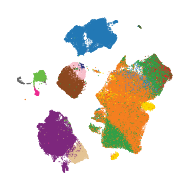

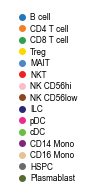

In [15]:
celltype_color_mapping = {
    'B cell': "#2278B5",
    #'B Naive': "#2278B5",
    #'B Intermediate/Memory': "#42B9EB",
    
    'CD4 T cell': "#F57F20",
    #'CD4 Naive': "#F7901E",
    #'CD4 Memory': "#F15A22",

    'CD8 T cell': "#2FA148",
    #'CD8 Naive': "#2FA148", #"#73BF98", #"#74AC42",
    #'CD8 Memory': "#17A57F",
    
    'Treg': "#FDD700",#"#7750A1",
    'MAIT': "#4C87C6",
    'NKT': "#ED2224",
    'NK CD56hi': "#F9BFCB",
    # 'CD56-bright NK': "#F9BFCB",
    'NK CD56low': "#8C471F",
    # 'CD56-dim NK': "#8C471F",
    'ILC': "#282A74",
    'pDC': "#ED2A91",
    'cDC': "#6ABD45",
    'CD14 Mono': "#7D277D",
    'CD16 Mono': "#E4C494",
    'HSPC': "#6A6A6A",
    # "Granulocyte": "#FDD700",
    # "other": "#FDD700",
    "Plasmablast": "#556B30",
    # "Platelet": "#FFFFFF",
    
}
embed_plot = embed_plot[embed_plot.obs.cell_type_v2_course != "Platelet"].copy()
fig, ax = plt.subplots(1,1,figsize=(2, 2))
sc.pl.umap(
    embed_plot,
    color="cell_type_v2_course",
    palette=celltype_color_mapping,
    ax=ax,
    size=2,
    legend_loc = None,
    # legend_loc="on data",
    show=False,
)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel(None)
ax.set_ylabel(None)
ax.set_title(None)
ax.set_frame_on(False)
ax.set_rasterization_zorder(2)
plt.tight_layout()
plt.savefig(
    os.path.join(fig_path, "umap.svg"), 
    bbox_inches="tight", 
    pad_inches=0, 
    dpi=500,
    transparent=True,
)
plt.show()

create_categorical_legend_figure(
    celltype_color_mapping,
    figsize=(0.8, 0.8),
    ncol=1,
    labelspacing=0.3,
    marker_size=4,
    handletextpad=0,
    path=os.path.join(fig_path, "umap_legend.svg"),
)

In [16]:
program_annotations = pd.read_excel(
    "/Users/soeren.becker/repos/HumanCytokineDict/notebooks/07_spatial/20250702_bio-annot-of-DRVIs_LV_latest.xlsx", 
    sheet_name=2
)

In [17]:
program_annotations

,Key Genes,Program,bio_annotation_fine,bio_annotation_coarse,Summary
0,"CXCL9, CXCL10, CXCL11, IL18",P91,Immune Cell Recruitment and Activation,Chemokine signaling,CS-01 Recruitment-1
1,"CCL2, CCL7, CCL8, CXCL1, CXCL3, CXCL6, CXCL8",P96,Chemotaxis and Immune Cell Recruitment,Chemokine signaling,CS-02 Recruitment-2
2,"EBI3, CCL22, CCL17, TAFA4",P105,Cytokine and Chemokine Signaling,Chemokine signaling,CS-03 MixedCytokine
3,"CCL18, CCL23, CCL26, CCL13",P111,Chemokine Signaling,Chemokine signaling,CS-04 Recruitment-3
4,"CCL2, XCR1, CCL7, PPBP",P101,Regulation of immune cell activation and chemo...,Chemokine signaling,CS-05 ImmuneReg
...,...,...,...,...,...
102,"NME1, MRPL12, MIF, HSPE1, C1QBP, HSPD1, PYCR1,...",P66,"Cellular Metabolism, Mitochondrial Function, a...",Other Biological Processes - Energy,OB-01 CellMetabolism
103,"CYP27A1, ME1, SLC7A11, TXNRD1, OSGIN1, LUCAT1,...",P126,Oxidative Stress Response and Metabolic Adapta...,"ER Stress, Oxidative and Metabolic Stress Resp...",ES-01 OxidativeStress
104,"DNAJB9, HSPA5, HYOU1, SEC24D, LARP1B, MANF",P80,ER Stress Response and Protein Folding,"ER Stress, Oxidative and Metabolic Stress Resp...",ES-02 ER-Stress
105,CFAP418-AS1,P135,NaN,To be excluded,EX-01 1


/Users/soeren.becker/micromamba/envs/env_gsea/lib/python3.10/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


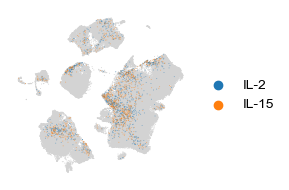

In [18]:
fig, ax = plt.subplots(1,1,figsize=(3, 2))

sc.pl.umap(
    embed_plot,
    palette=celltype_color_mapping,
    ax=ax,
    size=2,
    legend_loc = None,
    # legend_loc="on data",
    show=False,
)

sc.pl.umap(
    embed_plot[embed_plot.obs.cytokine.isin(["IL-2", "IL-15",])],
    color="cytokine",
    alpha=0.5,
    ax=ax,
    size=2,
    # legend_loc = None,
    # legend_loc="on data",
    show=False,
)

ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel(None)
ax.set_ylabel(None)
ax.set_title(None)
ax.set_frame_on(False)
ax.set_rasterization_zorder(2)
plt.tight_layout()
plt.show()

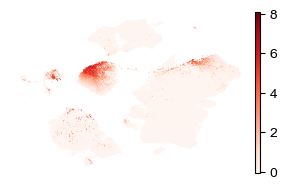

In [19]:
program_name = "CE-01 Cytotoxic-1"
program_dr = program_annotations.loc[program_annotations.Summary == program_name, "Program"].str.replace("P", "DR ").values[0]
fig, ax = plt.subplots(1,1,figsize=(3, 2))
sc.pl.umap(
    embed_plot,
    color=program_dr,
    ax=ax,
    size=2,
    legend_loc = None,
    # legend_loc="on data",
    show=False,
    cmap="Reds"
)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel(None)
ax.set_ylabel(None)
ax.set_title(None)
ax.set_frame_on(False)
ax.set_rasterization_zorder(2)
plt.tight_layout()
plt.show()

### boxplots of program activity

In [20]:
# define settings that are shared across all plots
de_anndata = sc.read_h5ad("/Users/soeren.becker/repos/HumanCytokineDict/notebooks/04_gene_programs/Amir/de_anndata_combined_v1.h5ad")

shared_kws = {
    "adata": de_anndata,
    "program_annotations": program_annotations,
    "show": True,
    "show_grid": False,
    "fontsize": 6,
    "aggregation": "mean",
    "cell_type_col": "cell_type",
    "cytokine_col": "cyt",
    "draw_zero_line": True,
    "xlabelrotation":  90,
    # "yticks": [-1, 0, 1],
    "ylim": [-1.05, 1.05],
    "layer": "diff_normalized_sig",
}

In [21]:
de_anndata.obs

,cell_type,donor,cyt,pbs
B cell / Donor1 / 4-1BBL / PBS-H10,B cell,Donor1,4-1BBL,PBS-H10
B cell / Donor1 / 4-1BBL / PBS-H11,B cell,Donor1,4-1BBL,PBS-H11
B cell / Donor1 / 4-1BBL / PBS-H12,B cell,Donor1,4-1BBL,PBS-H12
B cell / Donor1 / 4-1BBL / PBS-H7,B cell,Donor1,4-1BBL,PBS-H7
B cell / Donor1 / 4-1BBL / PBS-H8,B cell,Donor1,4-1BBL,PBS-H8
...,...,...,...,...
pDC / Donor8 / TL1A / PBS-H7,pDC,Donor8,TL1A,PBS-H7
pDC / Donor8 / TL1A / PBS-H8,pDC,Donor8,TL1A,PBS-H8
pDC / Donor8 / TSLP / PBS-H12,pDC,Donor8,TSLP,PBS-H12
pDC / Donor8 / TSLP / PBS-H7,pDC,Donor8,TSLP,PBS-H7


In [22]:
BOXPLOT_HEIGHT = 0.6

### CE-08 NK-Immuno

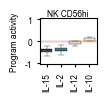

In [23]:
cell_type = "NK CD56hi"
program = "CE-08 NK-Immuno"

select = (
    (all_effects_df.cell_type == cell_type) 
    & (all_effects_df.process_id == program)
    & (all_effects_df.is_significant == 1)
)
cytokines = np.unique(all_effects_df.loc[select].cyt.astype(str).unique().tolist() + ["PBS"])
fig, df_program1 = make_boxplot(
    program_name=program,
    cell_types=cell_type,
    cytokines=cytokines,
    figsize=(2.5*(5/17), BOXPLOT_HEIGHT),
    path=os.path.join(fig_path, f"boxplot_{program}_{cell_type}_{shared_kws['aggregation']}-small.svg".replace(" ", "_")),
    ylabel="Program activity",
    yticks = [-1, 0, 1],
    yticklabels = [-1, 0, 1],
    title=f"{cell_type}",
    **shared_kws,

)

### II-05 ViralResponse

['IFN-β' 'IFN-ω' 'IL-7']


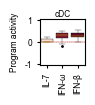

In [24]:
cell_type = ["cDC"]
program = "II-05 ViralResponse"

if isinstance(cell_type, str):
    cell_type = [cell_type]
select = (
    all_effects_df.cell_type.isin(cell_type)
    & (all_effects_df.process_id == program)
    & (all_effects_df.is_significant == 1)
)
cytokines = np.unique(all_effects_df.loc[select].cyt.astype(str).unique().tolist())
print(cytokines)
fig, df_program = make_boxplot(
    program_name=program,
    cell_types=cell_type,
    cytokines=cytokines,
    figsize=(2.5*(4/17), BOXPLOT_HEIGHT),
    path=os.path.join(fig_path, f"boxplot_{program}_{cell_type}_{shared_kws['aggregation']}.svg".replace(" ", "_")),
    **shared_kws,
    ylabel="Program activity",
    title=f"{cell_type[0]}",
    yticks = [-1, 0, 1],
    yticklabels = [-1, 0, 1],
)

['IFN-α1' 'IFN-β' 'IFN-γ' 'IFN-λ1' 'IFN-λ3' 'IFN-ω' 'IL-1-α' 'IL-1-β'
 'IL-10' 'IL-12' 'IL-13' 'IL-15' 'IL-2' 'IL-27' 'IL-32-β' 'IL-4' 'IL-7']


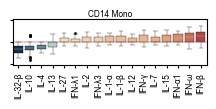

In [25]:
cell_type = ["CD14 Mono"]
program = "II-05 ViralResponse"

if isinstance(cell_type, str):
    cell_type = [cell_type]
select = (
    all_effects_df.cell_type.isin(cell_type)
    & (all_effects_df.process_id == program)
    & (all_effects_df.is_significant == 1)
)
cytokines = np.unique(all_effects_df.loc[select].cyt.astype(str).unique().tolist())
print(cytokines)
fig, df_program = make_boxplot(
    program_name=program,
    cell_types=cell_type,
    cytokines=cytokines,
    figsize=(2.5, BOXPLOT_HEIGHT),
    path=os.path.join(fig_path, f"boxplot_{program}_{cell_type}_{shared_kws['aggregation']}.svg".replace(" ", "_")),
    **shared_kws,
    ylabel="",
    title=f"{cell_type[0]}",
    yticks = [-1, 0, 1],
    yticklabels = [],
)

['GM-CSF' 'IFN-α1' 'IFN-β' 'IFN-ω' 'IL-1-α' 'IL-1-β' 'IL-10' 'IL-12'
 'IL-32-β' 'IL-4' 'IL-7']


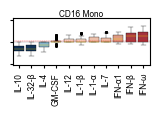

In [26]:
cell_type = ["CD16 Mono"]
program = "II-05 ViralResponse"

if isinstance(cell_type, str):
    cell_type = [cell_type]
select = (
    all_effects_df.cell_type.isin(cell_type)
    & (all_effects_df.process_id == program)
    & (all_effects_df.is_significant == 1)
)
cytokines = np.unique(all_effects_df.loc[select].cyt.astype(str).unique().tolist())
print(cytokines)
fig, df_program = make_boxplot(
    program_name=program,
    cell_types=cell_type,
    cytokines=cytokines,
    figsize=(2.5 * (12/17), BOXPLOT_HEIGHT),
    path=os.path.join(fig_path, f"boxplot_{program}_{cell_type}_{shared_kws['aggregation']}.svg".replace(" ", "_")),
    **shared_kws,
    ylabel="",
    title=f"{cell_type[0]}",
    yticks = [-1, 0, 1],
    yticklabels = [],
)

### CE-03 Cytotoxic-1

['IL-15' 'IL-2' 'IL-7']


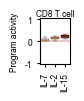

In [27]:
cell_type = ["CD8 T cell"]
program = "CE-01 Cytotoxic-1"

if isinstance(cell_type, str):
    cell_type = [cell_type]
select = (
    all_effects_df.cell_type.isin(cell_type)
    & (all_effects_df.process_id == program)
    & (all_effects_df.is_significant == 1)
)
cytokines = np.unique(all_effects_df.loc[select].cyt.astype(str).unique().tolist())
print(cytokines)
fig, df_program = make_boxplot(
    program_name=program,
    cell_types=cell_type,
    cytokines=cytokines,
    figsize=(2.5*(len(cytokines))/19, BOXPLOT_HEIGHT),
    path=os.path.join(fig_path, f"boxplot_{program}_{cell_type}_{shared_kws['aggregation']}.svg".replace(" ", "_")),
    **shared_kws,
    ylabel="Program activity",
    title=f"{cell_type[0]}",
    yticks = [-1, 0, 1],
    yticklabels = [-1, 0, 1],
)

['IL-15' 'IL-2' 'IL-7']


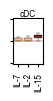

In [28]:
cell_type = ["cDC"]
program = "CE-01 Cytotoxic-1"

if isinstance(cell_type, str):
    cell_type = [cell_type]
select = (
    all_effects_df.cell_type.isin(cell_type)
    & (all_effects_df.process_id == program)
    & (all_effects_df.is_significant == 1)
)
cytokines = np.unique(all_effects_df.loc[select].cyt.astype(str).unique().tolist())
print(cytokines)
fig, df_program = make_boxplot(
    program_name=program,
    cell_types=cell_type,
    cytokines=cytokines,
    figsize=(2.5*(len(cytokines))/19, BOXPLOT_HEIGHT),
    path=os.path.join(fig_path, f"boxplot_{program}_{cell_type}_{shared_kws['aggregation']}.svg".replace(" ", "_")),
    **shared_kws,
    ylabel="",
    title=f"{cell_type[0]}",
    yticks = [-1, 0, 1],
    yticklabels = [],
)

['IL-15' 'IL-2' 'IL-7']


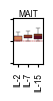

In [29]:
cell_type = ["MAIT"]
program = "CE-01 Cytotoxic-1"

if isinstance(cell_type, str):
    cell_type = [cell_type]
select = (
    all_effects_df.cell_type.isin(cell_type)
    & (all_effects_df.process_id == program)
    & (all_effects_df.is_significant == 1)
)
cytokines = np.unique(all_effects_df.loc[select].cyt.astype(str).unique().tolist())
print(cytokines)
fig, df_program = make_boxplot(
    program_name=program,
    cell_types=cell_type,
    cytokines=cytokines,
    figsize=(2.5*(len(cytokines))/19, BOXPLOT_HEIGHT),
    path=os.path.join(fig_path, f"boxplot_{program}_{cell_type}_{shared_kws['aggregation']}.svg".replace(" ", "_")),
    **shared_kws,
    ylabel="",
    title=f"{cell_type[0]}",
    yticks = [-1, 0, 1],
    yticklabels = [],
)

['IL-15' 'IL-2']


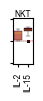

In [30]:
cell_type = ["NKT"]
program = "CE-01 Cytotoxic-1"

if isinstance(cell_type, str):
    cell_type = [cell_type]
select = (
    all_effects_df.cell_type.isin(cell_type)
    & (all_effects_df.process_id == program)
    & (all_effects_df.is_significant == 1)
)
cytokines = np.unique(all_effects_df.loc[select].cyt.astype(str).unique().tolist())
print(cytokines)
fig, df_program = make_boxplot(
    program_name=program,
    cell_types=cell_type,
    cytokines=cytokines,
    figsize=(2.5*(len(cytokines))/19, BOXPLOT_HEIGHT),
    path=os.path.join(fig_path, f"boxplot_{program}_{cell_type}_{shared_kws['aggregation']}.svg".replace(" ", "_")),
    **shared_kws,
    ylabel="",
    title=f"{cell_type[0]}",
    yticks = [-1, 0, 1],
    yticklabels = [],
)

['IFN-ω' 'IL-10' 'IL-12' 'IL-15' 'IL-2' 'IL-7']


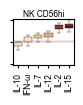

In [31]:
cell_type = ["NK CD56hi"]
program = "CE-01 Cytotoxic-1"

if isinstance(cell_type, str):
    cell_type = [cell_type]
select = (
    all_effects_df.cell_type.isin(cell_type)
    & (all_effects_df.process_id == program)
    & (all_effects_df.is_significant == 1)
)
cytokines = np.unique(all_effects_df.loc[select].cyt.astype(str).unique().tolist())
print(cytokines)
fig, df_program = make_boxplot(
    program_name=program,
    cell_types=cell_type,
    cytokines=cytokines,
    figsize=(2.5*(len(cytokines))/19, BOXPLOT_HEIGHT),
    path=os.path.join(fig_path, f"boxplot_{program}_{cell_type}_{shared_kws['aggregation']}.svg".replace(" ", "_")),
    **shared_kws,
    ylabel="",
    title=f"{cell_type[0]}",
    yticks = [-1, 0, 1],
    yticklabels = [],
)

['IFN-α1' 'IFN-β' 'IFN-γ' 'IFN-ω' 'IL-1-β' 'IL-10' 'IL-12' 'IL-15' 'IL-2'
 'IL-21' 'IL-3' 'IL-7']


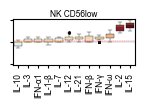

In [32]:
cell_type = ["NK CD56low"]
program = "CE-01 Cytotoxic-1"

if isinstance(cell_type, str):
    cell_type = [cell_type]
select = (
    all_effects_df.cell_type.isin(cell_type)
    & (all_effects_df.process_id == program)
    & (all_effects_df.is_significant == 1)
)
cytokines = np.unique(all_effects_df.loc[select].cyt.astype(str).unique().tolist())
print(cytokines)
fig, df_program = make_boxplot(
    program_name=program,
    cell_types=cell_type,
    cytokines=cytokines,
    figsize=(2.5*(len(cytokines))/19, BOXPLOT_HEIGHT),
    path=os.path.join(fig_path, f"boxplot_{program}_{cell_type}_{shared_kws['aggregation']}.svg".replace(" ", "_")),
    **shared_kws,
    ylabel="",
    title=f"{cell_type[0]}",
    yticks = [-1, 0, 1],
    yticklabels = [],
)

### CE-03 Cytotoxic-2

['IFN-β' 'IFN-ω']


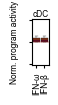

In [33]:
cell_type = ["cDC"]
program = "CE-03 Cytotoxic-2"

if isinstance(cell_type, str):
    cell_type = [cell_type]
select = (
    all_effects_df.cell_type.isin(cell_type)
    & (all_effects_df.process_id == program)
    & (all_effects_df.is_significant == 1)
)
cytokines = np.unique(all_effects_df.loc[select].cyt.astype(str).unique().tolist())
print(cytokines)
fig, df_program = make_boxplot(
    program_name=program,
    cell_types=cell_type,
    cytokines=cytokines,
    figsize=(2.*(len(cytokines))/19, BOXPLOT_HEIGHT),
    path=os.path.join(fig_path, f"boxplot_{program}_{cell_type}_{shared_kws['aggregation']}.svg".replace(" ", "_")),
    **shared_kws,
    ylabel="Norm. program activity",
    title=f"{cell_type[0]}",
    yticks = [-1, 0, 1],
    yticklabels = [],
)

['IFN-β' 'IFN-γ' 'IFN-ω' 'IL-15' 'IL-2' 'IL-7']


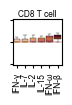

In [34]:
cell_type = ["CD8 T cell"]
program = "CE-03 Cytotoxic-2"

if isinstance(cell_type, str):
    cell_type = [cell_type]
select = (
    all_effects_df.cell_type.isin(cell_type)
    & (all_effects_df.process_id == program)
    & (all_effects_df.is_significant == 1)
)
cytokines = np.unique(all_effects_df.loc[select].cyt.astype(str).unique().tolist())
print(cytokines)
fig, df_program = make_boxplot(
    program_name=program,
    cell_types=cell_type,
    cytokines=cytokines,
    figsize=(2.*(len(cytokines))/19, BOXPLOT_HEIGHT),
    path=os.path.join(fig_path, f"boxplot_{program}_{cell_type}_{shared_kws['aggregation']}.svg".replace(" ", "_")),
    **shared_kws,
    ylabel="",
    title=f"{cell_type[0]}",
    yticks = [-1, 0, 1],
    yticklabels = [],
)

['IFN-β' 'IFN-ω']


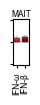

In [35]:
cell_type = ["MAIT"]
program = "CE-03 Cytotoxic-2"

if isinstance(cell_type, str):
    cell_type = [cell_type]

select = (
    all_effects_df.cell_type.isin(cell_type)
    & (all_effects_df.process_id == program)
    & (all_effects_df.is_significant == 1)
)
cytokines = np.unique(all_effects_df.loc[select].cyt.astype(str).unique().tolist())
print(cytokines)
fig, df_program = make_boxplot(
    program_name=program,
    cell_types=cell_type,
    cytokines=cytokines,
    figsize=(2.*(len(cytokines))/19, BOXPLOT_HEIGHT),
    path=os.path.join(fig_path, f"boxplot_{program}_{cell_type}_{shared_kws['aggregation']}.svg".replace(" ", "_")),
    **shared_kws,
    ylabel="",
    title=f"{cell_type[0]}",
    yticks = [-1, 0, 1],
    yticklabels = [],
)

['IFN-α1' 'IFN-β' 'IFN-γ' 'IFN-ω' 'IL-1-β' 'IL-15' 'IL-2' 'IL-27' 'IL-7']


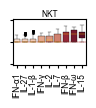

In [36]:
cell_type = ["NKT"]
program = "CE-03 Cytotoxic-2"

if isinstance(cell_type, str):
    cell_type = [cell_type]
select = (
    all_effects_df.cell_type.isin(cell_type)
    & (all_effects_df.process_id == program)
    & (all_effects_df.is_significant == 1)
)
cytokines = np.unique(all_effects_df.loc[select].cyt.astype(str).unique().tolist())
print(cytokines)
fig, df_program = make_boxplot(
    program_name=program,
    cell_types=cell_type,
    cytokines=cytokines,
    figsize=(2.*(len(cytokines))/19, BOXPLOT_HEIGHT),
    path=os.path.join(fig_path, f"boxplot_{program}_{cell_type}_{shared_kws['aggregation']}.svg".replace(" ", "_")),
    **shared_kws,
    ylabel="",
    title=f"{cell_type[0]}",
    yticks = [-1, 0, 1],
    yticklabels = [],
)

['IFN-β' 'IFN-γ' 'IFN-ω' 'IL-15' 'IL-2' 'IL-27' 'IL-32-β' 'IL-7']


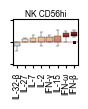

In [37]:
cell_type = ["NK CD56hi"]
program = "CE-03 Cytotoxic-2"

if isinstance(cell_type, str):
    cell_type = [cell_type]
select = (
    all_effects_df.cell_type.isin(cell_type)
    & (all_effects_df.process_id == program)
    & (all_effects_df.is_significant == 1)
)
cytokines = np.unique(all_effects_df.loc[select].cyt.astype(str).unique().tolist())
print(cytokines)
fig, df_program = make_boxplot(
    program_name=program,
    cell_types=cell_type,
    cytokines=cytokines,
    figsize=(2.*(len(cytokines))/19, BOXPLOT_HEIGHT),
    path=os.path.join(fig_path, f"boxplot_{program}_{cell_type}_{shared_kws['aggregation']}.svg".replace(" ", "_")),
    **shared_kws,
    ylabel="",
    title=f"{cell_type[0]}",
    yticks = [-1, 0, 1],
    yticklabels = [],
)

['C5a' 'GM-CSF' 'IFN-α1' 'IFN-β' 'IFN-γ' 'IFN-ω' 'IL-1-α' 'IL-1-β' 'IL-10'
 'IL-12' 'IL-15' 'IL-2' 'IL-21' 'IL-27' 'IL-4' 'IL-7' 'M-CSF']


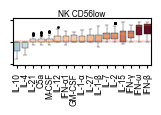

In [38]:
cell_type = ["NK CD56low"]
program = "CE-03 Cytotoxic-2"

if isinstance(cell_type, str):
    cell_type = [cell_type]
select = (
    all_effects_df.cell_type.isin(cell_type)
    & (all_effects_df.process_id == program)
    & (all_effects_df.is_significant == 1)
)
cytokines = np.unique(all_effects_df.loc[select].cyt.astype(str).unique().tolist())
print(cytokines)
fig, df_program = make_boxplot(
    program_name=program,
    cell_types=cell_type,
    cytokines=cytokines,
    figsize=(2.*(len(cytokines))/19, BOXPLOT_HEIGHT),
    path=os.path.join(fig_path, f"boxplot_{program}_{cell_type}_{shared_kws['aggregation']}.svg".replace(" ", "_")),
    **shared_kws,
    ylabel="",
    title=f"{cell_type[0]}",
    yticks = [-1, 0, 1],
    yticklabels = [],
)

In [39]:
cell_type = ["CD14 Mono", "CD16 Mono", "cDC", "B cell", "CD4 T cell", "CD8 T cell", "Treg", "MAIT", "NKT", "NK CD56hi", "NK CD56low", "HSPC",]
program = "GR-01 lncRNA-Reg"
program_str = re.sub(r'([0-9])([A-Z])', r'\1 \2', re.sub(r'([a-z])([A-Z])', r'\1 \2', program.split(" ")[1]))

if isinstance(cell_type, str):
    cell_type = [cell_type]
select = (
    all_effects_df.cell_type.isin(cell_type)
    & (all_effects_df.process_id == program)
    & (all_effects_df.is_significant == 1)
)

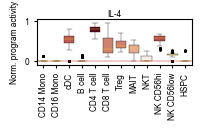

In [40]:
cell_type = ["CD14 Mono", "CD16 Mono", "cDC", "B cell", "CD4 T cell", "CD8 T cell", "Treg", "MAIT", "NKT", "NK CD56hi", "NK CD56low", "HSPC",]
program = "GR-01 lncRNA-Reg"
program_str = re.sub(r'([0-9])([A-Z])', r'\1 \2', re.sub(r'([a-z])([A-Z])', r'\1 \2', program.split(" ")[1]))

if isinstance(cell_type, str):
    cell_type = [cell_type]
select = (
    all_effects_df.cell_type.isin(cell_type)
    & (all_effects_df.process_id == program)
    & (all_effects_df.is_significant == 1)
)
_shared_kws = shared_kws.copy()
_shared_kws["yticks"] = [0, 1]
_shared_kws["ylim"] = [-0.1, 1.05]
cytokines = np.unique(all_effects_df.loc[select].cyt.astype(str).unique().tolist())
fig, df_program = make_boxplot(
    program_name=program,
    cell_types=cell_type,
    cytokines=cytokines,
    figsize=(2., BOXPLOT_HEIGHT),
    path=os.path.join(fig_path, f"boxplot_{program}_{cell_type}_{shared_kws['aggregation']}.svg".replace(" ", "_")),
    **_shared_kws,
    ylabel="Norm. program activity",
    title=f"{cytokines[0]}",
)

### Highest activity among all other cytokines for *GR-01 lncRNA-Reg*

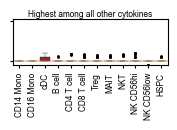

In [41]:
df_activity = _get_activity(
    adata=de_anndata[de_anndata.obs.cyt != "IL-4"],
    program_annotations=program_annotations,
    cell_type_col="cell_type",
    cell_types=None,
    program_name="GR-01 lncRNA-Reg",
    layer="diff_normalized_sig",
)
idcs = df_activity.groupby(["cell_type", "cyt"], observed=False)["activity"].mean().abs().groupby(level='cell_type', observed=False).idxmax()

best_of_rest = []
for idx in idcs:
    cell_type, cytokine = idx
    _df = _get_activity(
        adata=de_anndata[(de_anndata.obs.cyt == cytokine) & (de_anndata.obs.cell_type == cell_type)],
        program_annotations=program_annotations,
        cell_type_col="cell_type",
        cell_types=cell_type,
        program_name="GR-01 lncRNA-Reg",
        layer="diff_normalized_sig",
    )
    _df["cyt"] = _df["cyt"].astype(object)
    _df.loc[:, "cyt"] = "best-of-rest"
    best_of_rest.append(_df)    

best_of_rest = pd.concat(best_of_rest, axis=0)
best_of_rest["cyt"] = best_of_rest["cyt"].astype("category")

cell_type = ["CD14 Mono", "CD16 Mono", "cDC", "B cell", "CD4 T cell", "CD8 T cell", "Treg", "MAIT", "NKT", "NK CD56hi", "NK CD56low", "HSPC",]
fig, df_program = make_boxplot(
    program_name=program,
    cell_types=cell_type,
    cytokines="best-of-rest",
    figsize=(2., BOXPLOT_HEIGHT),
    path=os.path.join(fig_path, f"boxplot_{program}_best_of_rest.svg".replace(" ", "_")),
    **_shared_kws,
    ylabel="",
    title=f"Highest among all other cytokines",
    df_program = best_of_rest,
    yticklabels = [],
)

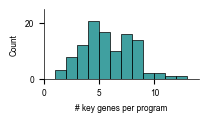

In [42]:
fig, ax = plt.subplots(1,1,figsize=(2, 0.9))
out = sns.histplot(
    program_annotations.loc[:, "Key Genes"].apply(lambda x: len(x.split(","))),
    bins=12,
    ax=ax,
    linewidth=0.5,
    color="teal"
)
ax.spines[['right', 'top']].set_visible(False)
ax.spines[['left', 'bottom']].set_linewidth(0.5)
ax.set_xticks(ax.get_xticks(), [str(int(s)) for s in ax.get_xticks()], fontsize=6, family="Arial")
ax.set_yticks(ax.get_yticks(), [str(int(s)) for s in ax.get_yticks()], fontsize=6, family="Arial")
plt.xlabel("# key genes per program", fontsize=6, family="Arial")
plt.ylabel("Count", fontsize=6, family="Arial")
plt.ylim([0, 25])
plt.xlim([0, 14])
if True:
    plt.savefig(
        os.path.join(fig_path, "key_gene_stats.svg"), 
        bbox_inches="tight", 
        pad_inches=0, 
        dpi=500,
        transparent=True,
    )
plt.show()

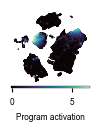

In [43]:
program_name = "CE-03 Cytotoxic-2"

cmap_umap = "mako"

program_dr = program_annotations.loc[program_annotations.Summary == program_name, "Program"].str.replace("P", "DR ").values[0]
fig, ax = plt.subplots(1,1,figsize=(1.1, 1.4))
sc.pl.umap(
    embed_plot,
    color=program_dr,
    ax=ax,
    size=2,
    legend_loc = None,
    cmap=cmap_umap,
    show=False,
    colorbar_loc="bottom",
)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel(None)
ax.set_ylabel(None)
ax.set_title(None)
ax.set_frame_on(False)
ax.set_rasterization_zorder(2)
cbar_ax = None
for _ax in fig.axes:
    if _ax != ax and _ax.get_label() == '<colorbar>':
        cbar_ax = _ax
        break
cbar_ax.tick_params(labelsize=6) 
for line in cbar_ax.get_lines():
    line.set_linewidth(0.)
if cbar_ax.get_ylabel():
    cbar_ax.set_ylabel(cbar_ax.get_ylabel(), fontsize=6)
    cbar_ax.set_xlabel(cbar_ax.get_xlabel(), fontsize=6)
for spine in cbar_ax.spines.values():
    spine.set_linewidth(0.25) 
    spine.set_edgecolor('black')

cbar_ax.set_xticks([0, 5])
cbar_ax.set_xticklabels(cbar_ax.get_xticklabels(), fontsize=6, family="Arial")
cbar_ax.tick_params(axis='both', which='both', length=3)
cbar_ax.set_xlabel("Program activation", fontsize=6, family="Arial")

program_str = re.sub(r'([0-9])([A-Z])', r'\1 \2', re.sub(r'([a-z])([A-Z])', r'\1 \2', program_name.split(" ")[1]))
# plt.title(program_str, fontsize=6, family="Arial")
plt.tight_layout()

if True:

    plt.savefig(
        os.path.join(fig_path, f"UMAP_{program_name}.svg"), 
        bbox_inches="tight", 
        pad_inches=0, 
        dpi=500,
        transparent=True,
    )
plt.show()

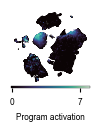

In [44]:
program_name = "CE-01 Cytotoxic-1"

cmap_umap = "mako"

program_dr = program_annotations.loc[program_annotations.Summary == program_name, "Program"].str.replace("P", "DR ").values[0]
fig, ax = plt.subplots(1,1,figsize=(1.1, 1.4))
sc.pl.umap(
    embed_plot,
    color=program_dr,
    ax=ax,
    size=2,
    legend_loc = None,
    cmap=cmap_umap,
    show=False,
    colorbar_loc="bottom",
)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel(None)
ax.set_ylabel(None)
ax.set_title(None)
ax.set_frame_on(False)
ax.set_rasterization_zorder(2)
cbar_ax = None
for _ax in fig.axes:
    if _ax != ax and _ax.get_label() == '<colorbar>':
        cbar_ax = _ax
        break
cbar_ax.tick_params(labelsize=6) 
for line in cbar_ax.get_lines():
    line.set_linewidth(0.)
if cbar_ax.get_ylabel():
    cbar_ax.set_ylabel(cbar_ax.get_ylabel(), fontsize=6)
    cbar_ax.set_xlabel(cbar_ax.get_xlabel(), fontsize=6)
for spine in cbar_ax.spines.values():
    spine.set_linewidth(0.25) 
    spine.set_edgecolor('black')

cbar_ax.set_xticks([0, 7])
cbar_ax.set_xticklabels(cbar_ax.get_xticklabels(), fontsize=6, family="Arial")
cbar_ax.tick_params(axis='both', which='both', length=3)
cbar_ax.set_xlabel("Program activation", fontsize=6, family="Arial")
program_str = re.sub(r'([0-9])([A-Z])', r'\1 \2', re.sub(r'([a-z])([A-Z])', r'\1 \2', program_name.split(" ")[1]))
# plt.title(program_str, fontsize=6, family="Arial")
plt.tight_layout()

if True:

    plt.savefig(
        os.path.join(fig_path, f"UMAP_{program_name}.svg"), 
        bbox_inches="tight", 
        pad_inches=0, 
        dpi=500,
        transparent=True,
    )
plt.show()

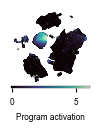

In [45]:
program_name = "CE-08 NK-Immuno"

cmap_umap = "mako"

program_dr = program_annotations.loc[program_annotations.Summary == program_name, "Program"].str.replace("P", "DR ").values[0]
fig, ax = plt.subplots(1,1,figsize=(1.1, 1.4))
sc.pl.umap(
    embed_plot,
    color=program_dr,
    ax=ax,
    size=2,
    legend_loc = None,
    cmap=cmap_umap,
    show=False,
    colorbar_loc="bottom",
)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel(None)
ax.set_ylabel(None)
ax.set_title(None)
ax.set_frame_on(False)
ax.set_rasterization_zorder(2)
cbar_ax = None
for _ax in fig.axes:
    if _ax != ax and _ax.get_label() == '<colorbar>':
        cbar_ax = _ax
        break
cbar_ax.tick_params(labelsize=6) 
for line in cbar_ax.get_lines():
    line.set_linewidth(0.)
if cbar_ax.get_ylabel():
    cbar_ax.set_ylabel(cbar_ax.get_ylabel(), fontsize=6)
    cbar_ax.set_xlabel(cbar_ax.get_xlabel(), fontsize=6)
for spine in cbar_ax.spines.values():
    spine.set_linewidth(0.25) 
    spine.set_edgecolor('black')

cbar_ax.set_xticks([0, 5])
cbar_ax.set_xticklabels(cbar_ax.get_xticklabels(), fontsize=6, family="Arial")
cbar_ax.tick_params(axis='both', which='both', length=3)
cbar_ax.set_xlabel("Program activation", fontsize=6, family="Arial")

program_str = re.sub(r'([0-9])([A-Z])', r'\1 \2', re.sub(r'([a-z])([A-Z])', r'\1 \2', program_name.split(" ")[1]))
# plt.title(program_str, fontsize=6, family="Arial")
plt.tight_layout()

if True:

    plt.savefig(
        os.path.join(fig_path, f"UMAP_{program_name}.svg"), 
        bbox_inches="tight", 
        pad_inches=0, 
        dpi=500,
        transparent=True,
    )
plt.show()

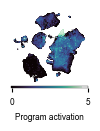

In [46]:
program_name = "GR-01 lncRNA-Reg"

cmap_umap = "mako"

program_dr = program_annotations.loc[program_annotations.Summary == program_name, "Program"].str.replace("P", "DR ").values[0]
fig, ax = plt.subplots(1,1,figsize=(1.1, 1.4))
sc.pl.umap(
    embed_plot,
    color=program_dr,
    ax=ax,
    size=2,
    legend_loc = None,
    cmap=cmap_umap,
    show=False,
    colorbar_loc="bottom",
)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel(None)
ax.set_ylabel(None)
ax.set_title(None)
ax.set_frame_on(False)
ax.set_rasterization_zorder(2)
cbar_ax = None
for _ax in fig.axes:
    if _ax != ax and _ax.get_label() == '<colorbar>':
        cbar_ax = _ax
        break
cbar_ax.tick_params(labelsize=6) 
for line in cbar_ax.get_lines():
    line.set_linewidth(0.)
if cbar_ax.get_ylabel():
    cbar_ax.set_ylabel(cbar_ax.get_ylabel(), fontsize=6)
    cbar_ax.set_xlabel(cbar_ax.get_xlabel(), fontsize=6)
for spine in cbar_ax.spines.values():
    spine.set_linewidth(0.25) 
    spine.set_edgecolor('black')

cbar_ax.set_xticks([0, 5])
cbar_ax.set_xticklabels(cbar_ax.get_xticklabels(), fontsize=6, family="Arial")
cbar_ax.tick_params(axis='both', which='both', length=3)
cbar_ax.set_xlabel("Program activation", fontsize=6, family="Arial")

program_str = re.sub(r'([0-9])([A-Z])', r'\1 \2', re.sub(r'([a-z])([A-Z])', r'\1 \2', program_name.split(" ")[1]))
# plt.title(program_str, fontsize=6, family="Arial")
plt.tight_layout()

if True:

    plt.savefig(
        os.path.join(fig_path, f"UMAP_{program_name}.svg"), 
        bbox_inches="tight", 
        pad_inches=0, 
        dpi=500,
        transparent=True,
    )
plt.show()

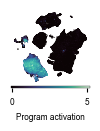

In [47]:
program_name = "II-05 ViralResponse"

cmap_umap = "mako"

program_dr = program_annotations.loc[program_annotations.Summary == program_name, "Program"].str.replace("P", "DR ").values[0]
fig, ax = plt.subplots(1,1,figsize=(1.1, 1.4))
sc.pl.umap(
    embed_plot,
    color=program_dr,
    ax=ax,
    size=2,
    legend_loc = None,
    cmap=cmap_umap,
    show=False,
    colorbar_loc="bottom",
)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel(None)
ax.set_ylabel(None)
ax.set_title(None)
ax.set_frame_on(False)
ax.set_rasterization_zorder(2)
cbar_ax = None
for _ax in fig.axes:
    if _ax != ax and _ax.get_label() == '<colorbar>':
        cbar_ax = _ax
        break
cbar_ax.tick_params(labelsize=6) 
for line in cbar_ax.get_lines():
    line.set_linewidth(0.)
if cbar_ax.get_ylabel():
    cbar_ax.set_ylabel(cbar_ax.get_ylabel(), fontsize=6)
    cbar_ax.set_xlabel(cbar_ax.get_xlabel(), fontsize=6)
for spine in cbar_ax.spines.values():
    spine.set_linewidth(0.25) 
    spine.set_edgecolor('black')

cbar_ax.set_xticks([0, 5])
cbar_ax.set_xticklabels(cbar_ax.get_xticklabels(), fontsize=6, family="Arial")
cbar_ax.tick_params(axis='both', which='both', length=3)
cbar_ax.set_xlabel("Program activation", fontsize=6, family="Arial")

program_str = re.sub(r'([0-9])([A-Z])', r'\1 \2', re.sub(r'([a-z])([A-Z])', r'\1 \2', program_name.split(" ")[1]))
# plt.title(program_str, fontsize=6, family="Arial")
plt.tight_layout()

if True:

    plt.savefig(
        os.path.join(fig_path, f"UMAP_{program_name}.svg"), 
        bbox_inches="tight", 
        pad_inches=0, 
        dpi=500,
        transparent=True,
    )
plt.show()

In [48]:
significant_effects_df = all_effects_df[all_effects_df['is_significant'] == 1]
significant_effects = significant_effects_df.title.unique()
sig_anndata = de_anndata[:, de_anndata.var.title.isin(significant_effects)]

In [49]:
sig_anndata.obs.cell_type.unique()

['B cell', 'CD14 Mono', 'CD16 Mono', 'CD4 T cell', 'CD8 T cell', ..., 'NKT', 'Plasmablast', 'Treg', 'cDC', 'pDC']
Length: 15
Categories (15, object): ['B cell', 'CD4 T cell', 'CD8 T cell', 'CD14 Mono', ..., 'Plasmablast', 'Treg', 'cDC', 'pDC']

##### Sanity check: a single cytokine should not be able to trigger up- and downregulation of the same program in a single cell type

In [50]:
overlaps = []

for cell_type in significant_effects_df.cell_type.unique():
    select_ct = (significant_effects_df.cell_type == "CD14 Mono")
    significant_effects_df_ct = significant_effects_df.loc[select_ct]
    for process in significant_effects_df_ct.process_id.unique():
        select_pid = (significant_effects_df_ct.process_id == process)
        cytos_up = significant_effects_df_ct.loc[select_pid & (significant_effects_df.direction == 1)].cyt.unique()
        cytos_down = significant_effects_df_ct.loc[select_pid & (significant_effects_df.direction == -1)].cyt.unique()
        cyto_overlap = np.intersect1d(cytos_up, cytos_down)
        overlaps.append(len(cyto_overlap))
        if len(cyto_overlap) > 0:
            print(cyto_overlap)
            assert False

assert np.all(np.array(overlaps) == 0)
print("Assertion passed!")

Assertion passed!


In [51]:
# mark as significant if any cytokine leads to significant effect in a given cell type and program, 
# separate for up- and down-regulation
map_significant_up = dict(all_effects_df.loc[all_effects_df.direction == 1].groupby(["cell_type", "process_id"])["is_significant"].max())
map_significant_down = dict(all_effects_df.loc[all_effects_df.direction == -1].groupby(["cell_type", "process_id"])["is_significant"].max())

In [52]:
sig_anndata.obs.cell_type.unique()

['B cell', 'CD14 Mono', 'CD16 Mono', 'CD4 T cell', 'CD8 T cell', ..., 'NKT', 'Plasmablast', 'Treg', 'cDC', 'pDC']
Length: 15
Categories (15, object): ['B cell', 'CD4 T cell', 'CD8 T cell', 'CD14 Mono', ..., 'Plasmablast', 'Treg', 'cDC', 'pDC']

In [53]:
df_scores = pd.DataFrame(sig_anndata.layers['diff_normalized_sig'], columns=sig_anndata.var.index)
# df_scores = pd.DataFrame(sig_anndata.layers['diff_normalized'], columns=sig_anndata.var.index)
df_scores.columns = get_program_names(list(df_scores.columns), program_annotations)
df_scores.loc[:, "cyt"] = sig_anndata.obs.loc[:, "cyt"].values
df_scores.loc[:, "cell_type"] = sig_anndata.obs.loc[:, "cell_type"].values
df_scores = df_scores.groupby(["cell_type", "cyt"], observed=False).mean().reset_index() # mean across donors and pbs wells

df_agg_max = df_scores.drop(labels="cyt", axis=1).groupby(["cell_type"], observed=False).max() # max across cytokines
df_agg_min = df_scores.drop(labels="cyt", axis=1).groupby(["cell_type"], observed=False).min() # min across cytokines

df_a = df_agg_max.stack().reset_index().rename({"level_1": "program", 0: "activity"}, axis=1)
df_a.loc[:, "significant"] = df_a.T.apply(lambda row: map_significant_up.get((row.cell_type, row.program), 0))
df_a = df_a.loc[df_a.significant == 1]
df_agg_max = df_a.pivot(index="cell_type", columns="program", values="activity")

df_b = df_agg_min.stack().reset_index().rename({"level_1": "program", 0: "activity"}, axis=1)
df_b.loc[:, "significant"] = df_b.T.apply(lambda row: map_significant_down.get((row.cell_type, row.program), 0))
df_b = df_b.loc[df_b.significant == 1]
df_agg_min = df_b.pivot(index="cell_type", columns="program", values="activity")

all_columns = df_agg_max.columns.union(df_agg_min.columns)

# Reindex both DataFrames to have all columns
df_max_full = df_agg_max.reindex(columns=all_columns)
df_min_full = df_agg_min.reindex(columns=all_columns)

# Fill missing rows in either df with NaNs to align indices
all_indices = sorted(set(df_max_full.index).union(df_min_full.index))

df_max_full = df_max_full.reindex(all_indices)
df_min_full = df_min_full.reindex(all_indices)

# Create new index with interleaved up/down labels
interleaved_dfs = []
new_index = []

for idx in all_indices:
    max_row = df_max_full.loc[[idx]]
    max_row.index = [f"{idx}-up"]
    min_row = df_min_full.loc[[idx]]
    min_row.index = [f"{idx}-down"]

    interleaved_dfs.extend([max_row, min_row])
    new_index.extend([f"{idx}-up", f"{idx}-down"])

interleaved_df = pd.concat(interleaved_dfs)

final_interleaved_df = interleaved_df

if True:
    _cell_type_order = [
        'B cell', 
        'CD4 T cell', 
        'CD8 T cell',
        'Treg',
        'MAIT',
        'NKT', 
        'NK CD56hi',
        'NK CD56low',
        'pDC',
        'cDC',
        'CD14 Mono',
        'CD16 Mono',
        'HSPC',
        'ILC', 
        'Plasmablast',
    ]

cell_type_order = []
significant_cell_types = all_effects_df.loc[all_effects_df.is_significant == 1].cell_type.unique()#combined_df.cell_type.unique()
for cell_type in _cell_type_order: # remove cell types without significant programs
    if cell_type in significant_cell_types:
        cell_type_order.append(cell_type)

cell_type_order = [
    idx + ("-up" if i%2==0 else "-down") 
    for i, idx in enumerate(np.repeat(cell_type_order, 2))
]
_final_interleaved_df = final_interleaved_df.copy()

_final_interleaved_df = _final_interleaved_df.loc[cell_type_order]
_final_interleaved_df.index = [
    idx.replace("-up", "").replace("-down", "") for idx in _final_interleaved_df.index
]
final_interleaved_df = _final_interleaved_df

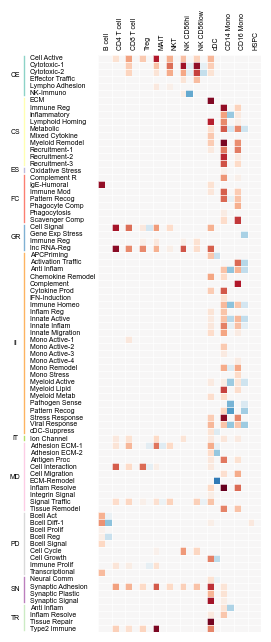

In [54]:
fig, ax = plt.subplots(1,1,figsize=(2.1,7.5))
df_heatmap = final_interleaved_df.T.sort_index()
df_heatmap.loc[:, "idx_category"] = [label.split(" ")[0].split("-")[0] for label in df_heatmap.index]
df_heatmap.loc[:, "idx_program"] = [label.split(" ")[1] for label in df_heatmap.index]
df_heatmap = df_heatmap.reset_index()
df_heatmap = df_heatmap.set_index(["idx_category", "idx_program"]).sort_index().set_index("program")
df_heatmap.fillna(0, inplace=True)

sns.heatmap(
    df_heatmap,
    ax=ax,
    cmap='RdBu_r',
    center=0, 
    lw=0.0,
    linecolor="white",
    square=False,
    fmt="",
    annot_kws={"fontsize": 5,},
    cbar=False,
)

__cmap = ax.collections[0].cmap
__norm = ax.collections[0].norm

for i in range(df_heatmap.shape[0]):
    ax.hlines(i, *ax.get_xlim(), colors='white', linewidth=0.5)
for i in range(0, df_heatmap.shape[1], 2):
    ax.vlines(i, *ax.get_ylim(), colors='white', linewidth=0.5)

ax.tick_params(axis='both', which='both', length=0)

new_xticklabels = df_heatmap.columns[::2]
plt.xticks(np.arange(1.25, 2*len(new_xticklabels), 2), new_xticklabels, fontsize=5, family="Arial", ha="center")

new_yticklables = [
    re.sub(
        r'([0-9])([A-Z])',
        r'\1 \2',
        re.sub(
            r'([a-z])([A-Z])', 
            r'\1 \2', 
            label.split(" ")[1]
        ) 
    ).replace("Ig E", "IgE").replace("c DC", "cDC")
    for label in list(df_heatmap.index)
]

plt.gca().set_yticks(
    0.51 + np.arange(len(new_yticklables)), 
    new_yticklables, 
    fontsize=5, 
    family="Arial", 
    ha="left",
    va="center",
)
yax = ax.get_yaxis()
pad = max(T.label1.get_window_extent().width for T in yax.majorTicks) - 16
yax.set_tick_params(pad=pad)

plt.xlabel("")
plt.ylabel("")
ax.tick_params(axis='both', which='both', length=0)
ax.tick_params(axis='x', top=True, bottom=False, labeltop=True, labelbottom=False, rotation=90)
fig.canvas.draw()
bbox = ax.get_position()

program_categories = [label.split(" ")[0].split("-")[0] for label in df_heatmap.index]
unique_program_categories = np.unique(program_categories)
# program_category_colors = all_palettes["Category20"][len(unique_program_categories)]
program_category_colors = all_palettes["Set3"][len(unique_program_categories)]
# program_category_colors = all_palettes["PRGn"][len(unique_program_categories)]

program_categories_map = dict(zip(unique_program_categories, range(len(unique_program_categories))))
program_idcs = [program_categories_map[label] for label in program_categories]
switch_idcs = [0] + list(np.where(np.diff(program_idcs))[0] + 1) + [len(program_idcs)]
switch_positions = (switch_idcs / np.max(switch_idcs)) * (bbox.y1 - bbox.y0)
x_line = -0.23
offset = bbox.y1 + 0.0005
gap=0.002
for k, (start, stop, name) in enumerate(
    zip(switch_positions[:-1], switch_positions[1:], unique_program_categories)
):
    linestart = offset-start-gap
    linestop = offset-stop+gap
    line = plt.Line2D(
        [x_line, x_line], 
        [linestart, linestop],
        transform=fig.transFigure, 
        color=program_category_colors[k],
        linewidth=1
    )
    fig.lines.append(line)
    y_center = linestart + (linestop - linestart)/2
    x_text = -0.27
    fig.text(y=y_center, x=x_text, s=name, ha='center', va="center", fontsize=5, family="Arial")

if True:
    plt.savefig(
        os.path.join(fig_path, "gene_program_both_sig.svg"), 
        bbox_inches="tight", 
        pad_inches=0, 
        dpi=500,
        transparent=True,
    )

plt.show()

-0.6070671456924441 0.8553616761360182


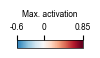

In [55]:
print(__norm.vmin, __norm.vmax)

# Create a new figure for the standalone colorbar
fig, cax = plt.subplots(figsize=(0.85, 0.1))  # Adjust size as needed

# Add the standalone colorbar
cb = plt.colorbar(plt.cm.ScalarMappable(norm=__norm, cmap=__cmap), cax=cax, orientation="horizontal", location="top")
cb.set_label('Max. activation', fontsize=6, family="Arial", )
labels = [-0.6, 0, 0.85]
cb.set_ticks(labels)
cb.set_ticklabels(labels, fontsize=6, family="Arial")
ax.tick_params(axis='both', which='both', length=1)

if False:
    cb.outline.set_visible(False)
cb.outline.set_linewidth(0.5)
cb.outline.set_edgecolor('black')

# 🔧 Optional: remove inner segment edges
cb.solids.set_edgecolor("face")

if True:
    plt.savefig(
        os.path.join(fig_path, "gene_program_both_sig_colorbar.svg"), 
        bbox_inches="tight", 
        pad_inches=0, 
        dpi=500,
        transparent=True,
    )
plt.show()

In [56]:
program_categories_map = [
    "CE: Cytotoxic effector function",
    "CS: Chemokine signaling", 
    "ES: ER, oxidative & metabolic stress response", 
    "FC: Fc, scavenger & complement receptors",
    "GR: Gene expression & regulation, cellular signaling",
    "II: Innate immune system & inflammation",
    "IT: Ion channel & transport",
    "MD: Membrance dynamics, adhesion & ECM remodeling",
    "PD: Proliferation, differentiation, development",
    "SN: Synaptic & neural signaling, synaptic plasticity",
    "TR: Tissue repair & inflammation resolution",
]

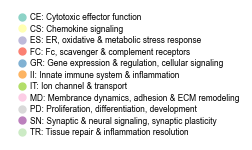

In [57]:
program_color_map = dict(zip(program_categories_map, program_category_colors))

create_categorical_legend_figure(
    program_color_map,
    figsize=(0.8, 0.8),
    ncol=1,
    labelspacing=0.3,
    fontsize=6,
    marker_size=5,
    handletextpad=0,
    path=os.path.join(fig_path, "heatmap_legend.svg"),
)

In [58]:
program_color_map

{'CE: Cytotoxic effector function': '#8dd3c7',
 'CS: Chemokine signaling': '#ffffb3',
 'ES: ER, oxidative & metabolic stress response': '#bebada',
 'FC: Fc, scavenger & complement receptors': '#fb8072',
 'GR: Gene expression & regulation, cellular signaling': '#80b1d3',
 'II: Innate immune system & inflammation': '#fdb462',
 'IT: Ion channel & transport': '#b3de69',
 'MD: Membrance dynamics, adhesion & ECM remodeling': '#fccde5',
 'PD: Proliferation, differentiation, development': '#d9d9d9',
 'SN: Synaptic & neural signaling, synaptic plasticity': '#bc80bd',
 'TR: Tissue repair & inflammation resolution': '#ccebc5'}

In [59]:
CELLTYPE = "CD8 T cell"
CYTOKINE = "IL-27"

significant_effects_df.loc[:, "abs_diff_normalized"] = significant_effects_df.loc[:, "diff_normalized"].abs()
select = (
    (significant_effects_df.cell_type == CELLTYPE)
    &(significant_effects_df.cyt == CYTOKINE)
)
display(significant_effects_df.loc[select].sort_values("abs_diff_normalized", ascending=False).head(3))

print(significant_effects_df.loc[select].is_significant.sum())

_programs = significant_effects_df.loc[select].sort_values("abs_diff_normalized", ascending=False).head(3).process_id.values.tolist()
display(_programs)

for p in program_annotations.loc[program_annotations.Summary.isin(_programs)].set_index("Summary").loc[_programs].bio_annotation_fine.values.tolist():
    print(p)

/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_79021/2351783813.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  significant_effects_df.loc[:, "abs_diff_normalized"] = significant_effects_df.loc[:, "diff_normalized"].abs()


,Unnamed: 0,cell_type,cyt,title,diff_normalized,n_diff_donors,direction,is_significant,process_id,abs_diff_normalized


0.0


[]

In [60]:
program_annotations.loc[program_annotations.Summary == "PD-12 ImmuneProlif", "bio_annotation_fine"].values[0]

'Immune Cell Activation, Proliferation, and Adhesion'

In [61]:
# significant_effects_df.to_csv("/Users/soeren.becker/repos/HumanCytokineDict/notebooks/03_gene_programs/Amir/significant_effects_df.csv")

### Shared effects

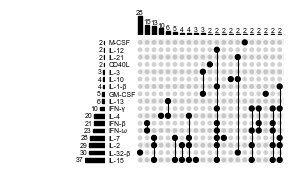

In [62]:
fontsize = 5

remove_cts = []#['HSPC']

manual_order = [
    'IL-32-β',
    'IL-10',
    'IL-21',
    'IL-13',
    'IL-4',
    'IL-7',
    'IL-15',
    'IL-2',
    'IFN-β',
    'IFN-ω',
    'IFN-γ',
    'IL-1-β',
    'IL-12',
    'IL-3',
    'GM-CSF',
    'CD40L',
    'M-CSF',
]

# Group by (cell_type, title), collect all cytokines
program_to_cytokines = (
    significant_effects_df
    .query('cell_type not in @remove_cts')
    .groupby(['cell_type', 'title'])['cyt']
    .apply(lambda x: set(x))
    .reset_index()
)
# Build memberships and program index
memberships = program_to_cytokines['cyt'].tolist()
program_index = list(zip(program_to_cytokines['cell_type'], program_to_cytokines['title']))
with pd.option_context('future.no_silent_downcasting', True):
    upset_series = from_memberships(memberships, data=pd.Series(1, index=program_index))

# Filter out subset combinations (columns) with count <= 1
freq = upset_series.reset_index().groupby(list(upset_series.index.names)).count()
freq = freq[freq > 1].dropna().index
filtered_upset_series = upset_series[upset_series.index.isin(freq)]

# Filter out unused cytokines
used_cyts = filtered_upset_series.reset_index().drop(columns=[0]).sum(axis=0)
unused_cyts = used_cyts[used_cyts == 0].index.tolist()
used_cyts = used_cyts[used_cyts >= 1].index.tolist()

filtered_upset_series = filtered_upset_series.reset_index().drop(columns=unused_cyts).set_index(used_cyts)[0]

fig = plt.figure(figsize=(2,4))
with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)
    plot_result = plot(
        pd.DataFrame(filtered_upset_series),
        fig=fig,
        element_size=10,
        totals_plot_elements=3,
        intersection_plot_elements=3,
        show_counts=True,
        subset_size='count',
        # totals_plot_elements=2,
        sort_by='cardinality',
        # sort_categories_by=None,
        sort_categories_by='cardinality',
    )

    w_factor = 0.65
    
    # Adjust top marginal plot
    intersections_ax = plot_result["intersections"]
    intersections_ax.set_ylabel("", fontsize=fontsize, family="Arial")
    intersections_ax.set_axis_off()
    pos = intersections_ax.get_position()
    intersections_ax.set_position([pos.x0, pos.y0-0.19, w_factor*pos.width, 0.75*pos.height])
    for text_obj in intersections_ax.texts:
        if text_obj.get_text().replace(',', '').isdigit(): 
            text_obj.set_fontsize(fontsize) 
            text_obj.set_family("Arial")

    # Adjust left marginal plot
    totals_ax = plot_result['totals']
    totals_ax.set_axis_off()
    pos = totals_ax.get_position()
    totals_ax.set_position([pos.x0 + 0.11, pos.y0, pos.width, pos.height])
    pos = totals_ax.get_position()
    totals_ax.set_position([pos.x0, pos.y0, w_factor*pos.width, 0.75*pos.height])
    for text_obj in plot_result['totals'].texts:
        if text_obj.get_text().replace(',', '').isdigit(): # Handles thousands separators
            text_obj.set_fontsize(fontsize) # Set your desired font size
            _pos = text_obj.get_position()
            text_obj.set_position([_pos[0] + 2, _pos[1]])
            text_obj.set_family("Arial")

    # Adjust center plot
    matrix_ax = plot_result['matrix']
    for collection in matrix_ax.collections:
        if isinstance(collection, LineCollection):    
            collection.set_linewidth(0.75)
    pos = matrix_ax.get_position()
    matrix_ax.set_position([pos.x0, pos.y0, w_factor*pos.width, 0.75*pos.height])
    ytick_labels = matrix_ax.get_yticklabels()
    for label in ytick_labels:
        label.set_horizontalalignment('left')
        x_pos, y_pos = label.get_position()
        label.set_x(-0.16)
        label.set_fontsize(fontsize)
        label.set_fontfamily("Arial")

    shading_ax = plot_result['shading']
    pos = shading_ax.get_position()
    # shading_ax.set_position([pos.x0, pos.y0, w_factor*pos.width, 0.75*pos.height])
    shading_ax.set_position([pos.x0-0.07, pos.y0, 0.85*pos.width, 0.75*pos.height])
    num_categories = len(filtered_upset_series.index.levels[0])
    shading_ax.set_xlim(-0.9, None)

if True:
    plt.savefig(
        os.path.join(fig_path, "shared_effects.svg"), 
        bbox_inches="tight", 
        pad_inches=0, 
        dpi=500,
        transparent=True,
    )
plt.show()

### programs by cell types

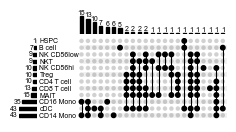

In [63]:
# Group by program title, collect all cell types it's found in
manual_order = [
    'CD16 Mono',
    'CD14 Mono',
    'cDC',
    'MAIT',
    'CD4 T cell',
    'CD8 T cell',
    'Treg',
    'NKT',
    'NK CD56low',
    'NK CD56hi',
    'B cell',
    'HSPC',
]

program_to_celltypes = (
    significant_effects_df
    .query('cell_type not in @remove_cts')
    .groupby('title')['cell_type']
    .apply(lambda x: set(x))
    .reset_index()
)

# Create memberships and series
with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)
    memberships = program_to_celltypes['cell_type'].tolist()
    titles = program_to_celltypes['title']
    upset_series = from_memberships(memberships, data=pd.Series(1, index=titles))
    upset_series = upset_series.reorder_levels(manual_order)
    
    fig = plt.figure(figsize=(2,4))

    plot_result = plot(
        pd.DataFrame(upset_series),
        fig=fig,
        element_size=9.2,
        totals_plot_elements=3,
        intersection_plot_elements=3,
        show_counts=True,
        subset_size='count',
        # totals_plot_elements=2,
        sort_by='cardinality',
        # sort_categories_by=None,
        sort_categories_by='cardinality',
    )

    w_factor = 0.65

    # Adjust top marginal plot
    intersections_ax = plot_result["intersections"]
    intersections_ax.set_ylabel("", fontsize=fontsize, family="Arial")
    intersections_ax.set_axis_off()
    pos = intersections_ax.get_position()
    intersections_ax.set_position([pos.x0, pos.y0-0.18, w_factor*pos.width, 0.75*pos.height])
    for text_obj in intersections_ax.texts:
        if text_obj.get_text().replace(',', '').isdigit(): 
            text_obj.set_fontsize(fontsize) 
            text_obj.set_family("Arial")


    # Adjust left marginal plot
    totals_ax = plot_result['totals']
    totals_ax.set_axis_off()
    pos = totals_ax.get_position()
    totals_ax.set_position([pos.x0 + 0.115, pos.y0, pos.width, pos.height])
    pos = totals_ax.get_position()
    totals_ax.set_position([pos.x0, pos.y0, w_factor*pos.width, 0.75*pos.height])
    for text_obj in plot_result['totals'].texts:
        if text_obj.get_text().replace(',', '').isdigit(): # Handles thousands separators
            text_obj.set_fontsize(fontsize) # Set your desired font size
            _pos = text_obj.get_position()
            text_obj.set_position([_pos[0] + 2, _pos[1]])
            text_obj.set_family("Arial")


    # Adjust center plot
    matrix_ax = plot_result['matrix']
    for collection in matrix_ax.collections:
        if isinstance(collection, LineCollection):    
            collection.set_linewidth(0.75)
    pos = matrix_ax.get_position()
    matrix_ax.set_position([pos.x0, pos.y0, w_factor*pos.width, 0.75*pos.height])
    ytick_labels = matrix_ax.get_yticklabels()
    for label in ytick_labels:
        label.set_horizontalalignment('left')
        x_pos, y_pos = label.get_position()
        label.set_x(-0.23)
        label.set_fontsize(fontsize)
        label.set_fontfamily("Arial")


    shading_ax = plot_result['shading']
    pos = shading_ax.get_position()
    shading_ax.set_position([pos.x0+0.262, pos.y0, 0.428*pos.width, 0.75*pos.height])
    num_categories = len(filtered_upset_series.index.levels[0])
    # shading_ax.set_xlim(-0.76, num_categories - 0.5)

if True:
    plt.savefig(
        os.path.join(fig_path, "shared_celltypes.svg"), 
        bbox_inches="tight", 
        pad_inches=0, 
        dpi=500,
        transparent=True,
    )

### How many programs is a gene part of?

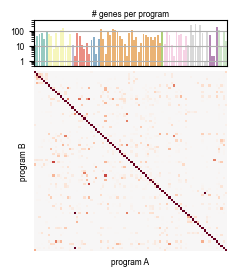

In [65]:
import matplotlib.gridspec as gridspec

interpretability_scores = pd.read_csv("/Users/soeren.becker/repos/HumanCytokineDict/data/drvi/interpretability_scores/combined_score_traverse_effect_pos.csv", index_col=0)
sig_scores = interpretability_scores.loc[:, sig_anndata.var.original_dim_id.values.astype(str)]
all_effects_df = pd.read_csv("/Users/soeren.becker/repos/HumanCytokineDict/notebooks/04_gene_programs/Amir/all_effects.csv", index_col=0)

program_categories_map_brief = [p.split(":")[0] for p in program_categories_map]

dim2title = dict(de_anndata.var.loc[:, ["original_dim_id", "title"]].values)
title2process = dict(all_effects_df.loc[:, ["title", "process_id"]].values)
program_category2color = dict(zip(list(program_categories_map_brief), program_category_colors))

THRESHOLD=0.5
sig_scores_thresholded = sig_scores.apply(lambda x: x > THRESHOLD).astype(int)
sig_scores_thresholded = sig_scores_thresholded.T.reset_index().astype(int).sort_values("index")
sig_scores_thresholded.index = sig_scores_thresholded.loc[:, "index"]
sig_scores_thresholded = sig_scores_thresholded.drop("index", axis=1).T

_program_order = df_heatmap.index
sig_scores_thresholded = sig_scores_thresholded.rename(dim2title, axis=1).rename(title2process, axis=1).T.loc[_program_order].T

overlap_matrix = sig_scores_thresholded.T.dot(sig_scores_thresholded)
num_genes_per_program = sig_scores_thresholded.sum(axis=0).values
fractions = overlap_matrix / num_genes_per_program
num_genes_per_program = pd.DataFrame(data=num_genes_per_program, index=overlap_matrix.columns, columns=["gene_count"])
num_genes_per_program.loc[:, "program_category"] = num_genes_per_program.index.str.split("-").str.get(0)
num_genes_per_program = num_genes_per_program.reset_index()

fig = plt.figure(figsize=(2.5, 3))
gs = gridspec.GridSpec(2, 1, height_ratios=[2.5, 10], hspace=0.05)

ax1 = plt.subplot(gs[1])
sns.heatmap(fractions.astype(float), cmap="RdBu_r", ax=ax1, cbar=False, center=0, square=False, lw=0.0, linecolor="white",)
ax1.set_xlabel("program A", fontsize=6, family="Arial")
ax1.set_ylabel("program B", fontsize=6, family="Arial")
ax1.set_xticks([])
ax1.set_yticks([])

__cmap = ax1.collections[0].cmap
__norm = ax1.collections[0].norm

ax0 = plt.subplot(gs[0])#, sharex=ax1)
ax0.grid()
sns.barplot(num_genes_per_program, x="program", y="gene_count", ax=ax0, palette=program_category2color, hue="program_category", legend=None)
ax0.set_yscale("log")
ax0.set_xlim([-0.5, len(num_genes_per_program)-0.5])
ax0.set_xticks([])
ax0.set_yticks([1, 10, 100], ["1", "10", "100"], fontsize=6, family="Arial")
ax0.set_ylim([0.5, 500])
# ax0.set_ylabel("# genes", fontsize=6, family="Arial")
ax0.set_ylabel("", fontsize=6, family="Arial")
ax0.set_xlabel("", fontsize=6, family="Arial")
ax0.set_title("# genes per program", fontsize=6, family="Arial", pad=3)

if True:
    plt.savefig(
        os.path.join(fig_path, "gene_overlap.svg"), 
        bbox_inches="tight", 
        pad_inches=0, 
        dpi=500,
        transparent=True,
    )

plt.show()

0.0 1.0


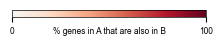

In [66]:
print(__norm.vmin, __norm.vmax)

# Create a new figure for the standalone colorbar
fig, cax = plt.subplots(figsize=(2.5, 0.1))  # Adjust size as needed

# Add the standalone colorbar
cb = plt.colorbar(plt.cm.ScalarMappable(norm=__norm, cmap=__cmap), cax=cax, orientation="horizontal", location="bottom")
cb.set_label('% genes in A that are also in B', fontsize=6, family="Arial", labelpad=-7)
labels = [0, 1]
labels_percent = np.array([0, 1])*100
cb.set_ticks(labels)
cb.set_ticklabels(labels_percent, fontsize=6, family="Arial")
ax.tick_params(axis='both', which='both', length=1)

if False:
    cb.outline.set_visible(False)
cb.outline.set_linewidth(0.5)
cb.outline.set_edgecolor('black')

# 🔧 Optional: remove inner segment edges
cb.solids.set_edgecolor("face")

if True:
    plt.savefig(
        os.path.join(fig_path, "gene_overlap_colorbar.svg"), 
        bbox_inches="tight", 
        pad_inches=0, 
        dpi=500,
        transparent=True,
    )

plt.show()